# Training without labels

**Question:** How can a network learn holograms without example holograms, and what does its held-out record show?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (what the network takes and returns) and notebook 01 of topic 03-gerchberg-saxton (the loop on traps)
- **Reading time:** about 50 minutes; the notebook runs in about 40 seconds

## Objectives

Supervised learning needs pairs: an input and the answer the network should have given. For a hologram there is no such answer to collect, because the best phase mask for a target is exactly the thing that is expensive to compute, and many masks make nearly the same light. The released network sidesteps the problem. It is trained with a loss that needs only the target: it asks the optics, through the forward model, what light the network's own mask makes, and scores that light against the target. You will compute that loss by hand on fresh volumes, see that it separates an informed mask from an uninformed one and rises smoothly around the network's phase, see what it fails to measure, read the training record and the held-out evidence that the product committed, and check that the file under test is the file the record describes. You will end able to say what the held-out record supports and what it does not.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.31.1
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The network is the product's released ONNX graph, read through onnxruntime. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import hashlib
import importlib.metadata as md
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.holo.core import forward, metrics, modes
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.learned import convert, evaluation, generators
from pipeline.model.holo.methods.baseline import m04_gs

for name in ("numpy", "matplotlib", "onnxruntime"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.31.1


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic. The volumes are drawn by the product's seeded generator, the same family the network was trained on, and no third-party dataset applies; the repository licence covers every file.
- Files read: `models/cgh-net.onnx` and its card `models/cgh-net.json`, the training record `data/derived/models/cgh-net-training.json` and the held-out detail `data/derived/models/evaluation-detail.json`. The last two are the product's committed evidence, read here as evidence and never used to compute the lessons of the first half.

The next cell reads the four files, opens the graph, and fixes the geometry of the evaluation (a 128 by 128 SLM with no padding, the three depths of training) from the product's evaluation module.

In [2]:
# the released graph, its card, the training record and the held-out detail, read as evidence
def read_json(*parts):
    return json.loads(ROOT.joinpath(*parts).read_text(encoding="utf-8"))


card = read_json("models", "cgh-net.json")
training = read_json("data", "derived", "models", "cgh-net-training.json")
detail = read_json("data", "derived", "models", "evaluation-detail.json")["cgh-net"]
session = ort.InferenceSession(str(ROOT / "models" / "cgh-net.onnx"), providers=["CPUExecutionProvider"])
setup, DEPTHS = evaluation.SETUP128, (-8, 0, 8)
zr = convert.rayleigh_range_m(setup)
print("held-out volumes in the detail:", len(detail["rows"]))
print("training record keys:", ", ".join(sorted(training)))

held-out volumes in the detail: 162
training record keys: config, heldout_sha256, onnx_bytes, operators, opset, parity_intensity_rel_max, parity_wrapped_abs_diff, slot, steps


## Method

**The loss.** With $T_p$ the target image at plane $p$ and $I_p(\phi)$ the intensity that the phase mask $\phi$ makes there, both scaled to unit sum, the network is trained to minimise $L(\phi) = 1 - \frac{1}{3}\sum_p 2\sum T_p I_p / (\sum T_p^2 + \sum I_p^2)$, the accuracy measure of DeepCGH (Eybposh et al. 2020, https://doi.org/10.1364/OE.399624) as the product reads it. The plane image is $I_p = |\mathcal{F}\{A\,e^{i(\phi - \phi_{z_p})}\}|^2$ with $\phi_{z_p}$ the lens term of depth $z_p$. Nothing in $L$ is a stored hologram: a training example is a target, and the "answer" is computed from the network's own output. Every step of the chain is differentiable, so the gradient of $L$ reaches the weights; the product's training stage did that with a deep-learning library that this notebook environment does not carry, so the training itself is read from its record here and not run.

**What a label-free loss can and cannot ask.** It can ask for light that overlaps the target images. It cannot ask for anything the loss does not contain: the intensity of each trap, the power in the traps, the uniformity. Whatever the network does about those is a side effect of the overlap, and the later steps measure it.

The first step computes $L$ for one volume by hand. The cell draws 24 volumes from the product's generator with a fixed seed, six of each kind (random sets, shifted lattices, rings and mixed), runs the network on the second one, a lattice, refocuses its phase to each depth with the engine's lens term and focal FFT, and prints the overlap of each plane and the loss, next to the loss from the product's own function.

In [3]:
# the loss of one volume by hand: refocus the network's phase to each depth, then overlap with the target
def network_phase(amps):
    return session.run(None, {"target": amps[None]})[0][0, 0].astype(np.float64)


def unit_sum(image):
    return image / image.sum()


def overlap(goal, got):
    return 2 * np.sum(goal * got) / (np.sum(goal**2) + np.sum(got**2))


rng = np.random.default_rng(20261104)
volumes = [(kind, *generators.sample_volume(rng, kind)) for kind in ("random", "lattice", "ring", "mixed") * 6]
kind, amps, _ = volumes[1]
phase = network_phase(amps)
lens = {z: modes.lens_phase(setup, z * zr) for z in DEPTHS}
goals = [unit_sum(a.astype(float) ** 2) for a in amps]
images = [unit_sum(np.abs(forward.fft_focal_field(phase - lens[z], setup)) ** 2) for z in DEPTHS]
per_plane = [overlap(g, i) for g, i in zip(goals, images)]
print(f"volume of kind {kind}: overlap per plane", np.round(per_plane, 4).tolist())
print(f"loss 1 - AC by hand: {1 - np.mean(per_plane):.4f}")
print(f"loss by the product's function: {1 - evaluation.plane_accuracy(amps, phase):.4f}")

volume of kind lattice: overlap per plane [0.7854, 0.8069, 0.7006]
loss 1 - AC by hand: 0.2357
loss by the product's function: 0.2357


The overlaps are 0.7854, 0.8069 and 0.7006 on the three planes, and the loss, 0.2357, is the same by hand and by the product's function, so what the notebook computes from here on is the quantity the network was trained on. The figure puts the target of this volume above the image the network's phase makes, for each depth, with the overlap of the plane in the title.

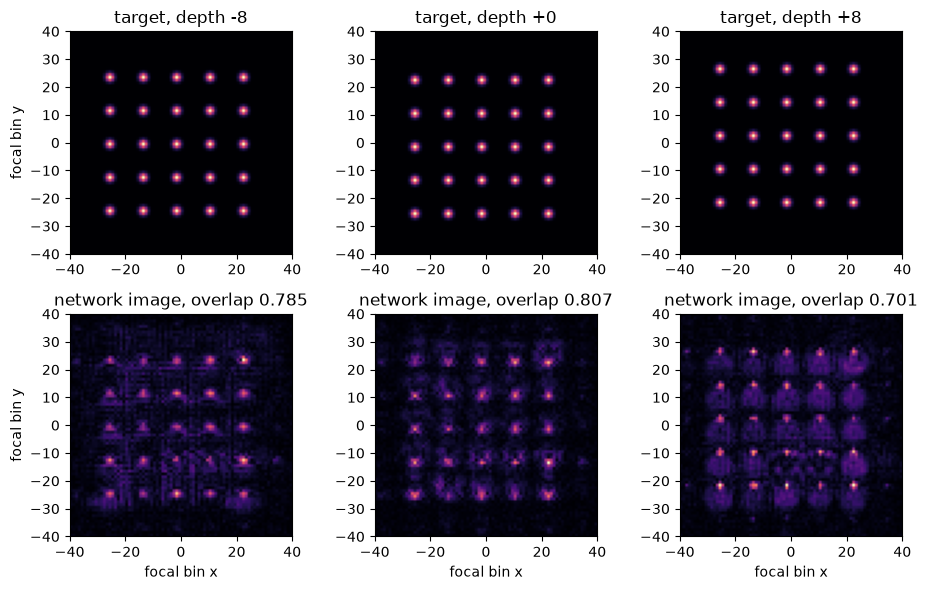

In [4]:
# the target and the network's image at each depth for that volume, with the overlap of each plane
fig, axes = plt.subplots(2, 3, figsize=(9.5, 6))
for k, z in enumerate(DEPTHS):
    axes[0, k].imshow(goals[k][24:104, 24:104], cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    axes[1, k].imshow(np.sqrt(images[k][24:104, 24:104]), cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    axes[0, k].set_title(f"target, depth {z:+d}")
    axes[1, k].set_title(f"network image, overlap {per_plane[k]:.3f}")
    axes[1, k].set_xlabel("focal bin x")
axes[0, 0].set_ylabel("focal bin y")
axes[1, 0].set_ylabel("focal bin y")
fig.tight_layout()
plt.show()

The target is a lattice of 25 spots per plane, shifted from plane to plane; the network's image carries the lattice at every depth, with spots of uneven brightness, each trailed by a halo, and with the plane at +8 the muddiest, which is also the one with the lowest overlap, 0.7006. The loss is a single number made of these three pictures, and a picture can be wrong in several ways at once: a dim spot, a smeared one, a haze between spots. The figure does not show which of those the loss penalises most. The next step asks whether the loss separates a mask that knows the target from one that does not, on all 24 volumes, with a flat phase and a random phase as the uninformed masks.

In [5]:
# the loss on 24 fresh volumes for the network, a flat phase and a random phase
losses = {"cgh-net": [], "flat phase": [], "random phase": []}
for kind, amps, _ in volumes:
    net = network_phase(amps)
    goals = [unit_sum(a.astype(float) ** 2) for a in amps]
    for name, phi in zip(losses, (net, np.zeros_like(net), rng.uniform(-np.pi, np.pi, net.shape))):
        got = [unit_sum(np.abs(forward.fft_focal_field(phi - lens[z], setup)) ** 2) for z in DEPTHS]
        losses[name].append(1 - np.mean([overlap(g, i) for g, i in zip(goals, got)]))
for name, values in losses.items():
    print(f"{name:12s} loss: median {np.median(values):.4f}, range {min(values):.4f} to {max(values):.4f}")

cgh-net      loss: median 0.3102, range 0.1946 to 0.3796
flat phase   loss: median 0.9999, range 0.7737 to 1.0000
random phase loss: median 0.9829, range 0.9483 to 0.9955


The median loss of the network is 0.3102, with a range from 0.1946 to 0.3796, against 0.9999 for a flat phase and 0.9829 for a random phase; even the best of the uninformed masks, 0.7737 for a flat phase, is far above the worst network result. The loss separates the two kinds of mask by a wide margin on every volume, so it carries the information a learner needs. The next step asks a different question: is the network's phase a point the loss likes, or one it merely passes through? The cell adds noise of growing size, from 0 to 1.6 rad per pixel, to the network's phase on one volume of each kind and recomputes the loss.

In [6]:
# the loss around the network's phase: noise of growing size added to the phase of four volumes
sizes = (0.0, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6)
noise = np.random.default_rng(3).standard_normal((128, 128))
around = {}
for kind, amps, _ in volumes[:4]:
    net = network_phase(amps)
    goals = [unit_sum(a.astype(float) ** 2) for a in amps]
    around[kind] = []
    for s in sizes:
        got = [unit_sum(np.abs(forward.fft_focal_field(net + s * noise - lens[z], setup)) ** 2) for z in DEPTHS]
        around[kind].append(1 - np.mean([overlap(g, i) for g, i in zip(goals, got)]))
    print(f"{kind:8s}", " ".join(f"{v:.4f}" for v in around[kind]))
print("noise sizes (rad):", sizes)

random   0.2825 0.2833 0.2858 0.2959 0.3388 0.5227 0.8978
lattice  0.2357 0.2365 0.2387 0.2476 0.2868 0.4727 0.8888
ring     0.2933 0.2940 0.2962 0.3052 0.3447 0.5274 0.9241
mixed    0.2862 0.2870 0.2894 0.2992 0.3415 0.5230 0.8944
noise sizes (rad): (0.0, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6)


Each row is one volume and each column one noise size, 0, 0.05, 0.1, 0.2, 0.4, 0.8 and 1.6 rad; the loss of the random volume goes from 0.2825 to 0.2833, 0.2858, 0.2959, 0.3388, 0.5227 and 0.8978. The figure draws the four volumes on a symmetric logarithmic axis for the noise.

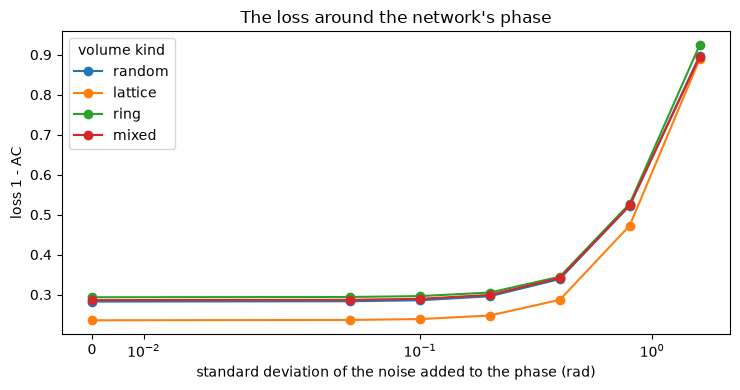

In [7]:
# the same four curves: the loss against the size of the noise added to the phase
fig, ax = plt.subplots(figsize=(7.5, 4))
for kind, values in around.items():
    ax.plot(sizes, values, "o-", label=kind)
ax.set_xscale("symlog", linthresh=0.05)
ax.set_xlabel("standard deviation of the noise added to the phase (rad)")
ax.set_ylabel("loss 1 - AC")
ax.set_title("The loss around the network's phase")
ax.legend(title="volume kind")
fig.tight_layout()
plt.show()

All four curves are flat for noise below 0.1 rad, climb gently up to 0.4 rad and then rise steeply, to between 0.8888 and 0.9241 at 1.6 rad, close to the median loss of a random mask, 0.9829; the curves for the four kinds have almost the same shape, apart from the lattice sitting lower. Noise never lowered the loss, so the network's phase is not at a place where a random nudge helps, and the loss around it is a smooth bowl, which is what a gradient method needs. The figure tests one noise draw per volume and random directions only: it does not show that the phase is a minimum, since a descent direction could exist that noise does not find. The next step looks at what the loss leaves out, the traps themselves, and compares the network with M04, the plain Gerchberg-Saxton loop, run for 30 iterations on the same volumes.

In [8]:
# what the loss does not see: the traps' own efficiency and uniformity, network against M04 on the same volumes
trap_view = {"cgh-net": [], "M04": []}
for kind, amps, points in volumes:
    target = evaluation.volume_target(points)
    gs = m04_gs.run(setup, target, budget=Budget(30), rng=Rng(1))
    for name, phi in (("cgh-net", network_phase(amps)), ("M04", gs.phi)):
        weighted = metrics.trap_intensities(forward.point_trap_fields(phi, setup, target.traps), target.traps.weight)
        eff, uni = metrics.efficiency(weighted), metrics.uniformity(weighted)
        trap_view[name].append((eff, uni, evaluation.plane_accuracy(amps, phi)))
for name, rows in trap_view.items():
    eff, uni, acc = np.median(np.array(rows), axis=0)
    print(f"{name:8s} median efficiency {eff:.3f}, uniformity {uni:.3f}, accuracy {acc:.3f}")

cgh-net  median efficiency 0.388, uniformity 0.558, accuracy 0.690
M04      median efficiency 0.745, uniformity 0.803, accuracy 0.606


On the same 24 volumes the network has the higher accuracy, 0.690 against 0.606 for M04, and the lower efficiency, 0.388 against 0.745, and the lower uniformity, 0.558 against 0.803. The two views rank the holograms in opposite order, as expected from a loss that contains the first and not the others: the network puts a little over a third of the light into the traps and is better at the images, while the classical loop puts three quarters into the traps and is better at making them equal. No label would have said otherwise, because a label-free loss asks only what its formula holds. This is a statement about 24 volumes and 30 iterations of M04, and it does not say what a differently weighted loss would do. Next, how the loss of the classical loop moves with its iterations on the lattice volume of the first step, against the single pass of the network.

In [9]:
# a classical loop given iterations: M04's loss on the lattice volume after 1, 5, 10, 30 and 100 iterations
kind, amps, points = volumes[1]
target = evaluation.volume_target(points)
phi_now, done, curve = None, 0, {}
for stop in (1, 5, 10, 30, 100):
    run = m04_gs.run(setup, target, budget=Budget(stop - done), rng=Rng(1), init=phi_now)
    phi_now, done = run.phi, stop
    curve[stop] = 1 - evaluation.plane_accuracy(amps, phi_now)
    print(f"M04 after {stop:3d} iterations: loss {curve[stop]:.4f}")
print(f"the network, one pass: loss {1 - evaluation.plane_accuracy(amps, network_phase(amps)):.4f}")

M04 after   1 iterations: loss 0.3657
M04 after   5 iterations: loss 0.3511
M04 after  10 iterations: loss 0.3475
M04 after  30 iterations: loss 0.3450
M04 after 100 iterations: loss 0.3452
the network, one pass: loss 0.2357


M04 scores a loss of 0.3657 after one iteration, 0.3511 after 5, 0.3475 after 10, 0.3450 after 30 and 0.3452 after 100: it settles near 0.345 within thirty iterations and stays there, while the network's single pass gives 0.2357 on this volume. Gerchberg-Saxton does not optimise this loss, since it projects between the focal plane and the SLM and keeps the phase, and on this volume its projections stagnate above what a pass of the network reaches. That is the value of training against the loss itself, and also its limit: it is one volume and one start of M04, and the traps' own numbers of the previous step went the other way. The training record says how much the network was shown. The cell prints the steps, the batch, the seeds and the limits that the product wrote when it trained the graph, how many volumes that makes, and the two parity numbers the export step stored.

In [10]:
# what the training record states: how many volumes the network saw and under which seeds and limits
config = training["config"]
seen = config["steps"] * config["batch"]
parity = training["parity_wrapped_abs_diff"]
print(f"steps {config['steps']} x batch {config['batch']} = {seen} volumes drawn on the fly")
print(f"learning rate {config['lr']}, data seed {config['data_seed']}")
print(f"initialisation seed {config['init_seed']}, time cap {config['max_hours']} h")
print(f"ONNX operators in the graph: {len(training['operators'])}")
print("parity on the plane intensities, largest relative difference:")
print(f"    {training['parity_intensity_rel_max']:.2e}")
print(f"share of phase pixels differing by over 1e-5: {parity['share_above_1e-5']:.3f}")

steps 16000 x batch 32 = 512000 volumes drawn on the fly
learning rate 0.001, data seed 20261103
initialisation seed 13, time cap 2.2 h
ONNX operators in the graph: 19
parity on the plane intensities, largest relative difference:
    8.42e-06
share of phase pixels differing by over 1e-5: 0.280


The network saw 16000 steps of 32 volumes, 512000 volumes, each sorted on the fly from the seeded generator, with data seed 20261103 and initialisation seed 13: no dataset was stored, and the data of the run can be redrawn from its seed. The exported graph holds 19 kinds of operator. Its parity with the training framework is stated on the plane intensities, a largest relative difference of 8.42e-06, and not on the phase, because 0.280 of the phase pixels differ by more than 1e-5 after wrapping: the phase is ill-conditioned where the SLM field is nearly zero, and what must agree is the light, which does. This is the committed record of one run, and the notebook did not repeat the run. Next, the held-out evidence: 162 volumes written before training with other seeds, on which the product compared the network alone with the volumetric GS (M19) given the same wall clock. The cell reads the per-volume accuracies.

In [11]:
# the held-out record: accuracy of the network alone and of volumetric GS at equal wall clock
rows = detail["rows"]
net = np.array([r["ac_net_alone"] for r in rows])
m19 = np.array([r["ac_m19_matched"] for r in rows])
ratio = net / m19
print(f"volumes {len(rows)}, median accuracy: network {np.median(net):.4f}, M19 {np.median(m19):.4f}")
print(f"ratio network / M19: median {np.median(ratio):.4f}, smallest {ratio.min():.4f}, largest {ratio.max():.4f}")
print(f"share of volumes where the network is above M19: {np.mean(ratio > 1):.3f}")
print(f"iterations M19 got in the wall clock: median {detail['m19_matched_iterations_median']:.0f}")
print(f"wall clock of M19 {detail['wall_clock_budget_ms']:.0f} ms")
print(f"network pass: median {detail['network_ms_median']:.0f} ms")

volumes 162, median accuracy: network 0.6869, M19 0.5997
ratio network / M19: median 1.1400, smallest 1.0654, largest 1.2603
share of volumes where the network is above M19: 1.000
iterations M19 got in the wall clock: median 37
wall clock of M19 7355 ms
network pass: median 35 ms


Over the 162 held-out volumes the median accuracy is 0.6869 for the network and 0.5997 for M19, the median ratio is 1.1400, the smallest ratio is 1.0654 and the network is above M19 on every volume, a share of 1.000. M19 had a wall clock of 7355 ms that gave it a median of 37 iterations, and the network alone took a median of 35 ms. Next, how the ratio depends on the kind of volume and on the share of the wall clock the loop is given.

In [12]:
# the same record by kind of volume, and against the share of the wall clock given to the loop
kinds = np.array([r["volume"].split("/")[1] for r in rows])
for kind in sorted(set(kinds)):
    part = ratio[kinds == kind]
    print(f"{kind:8s} n = {part.size:3d}  ratio: median {np.median(part):.4f}, smallest {part.min():.4f}")
for label, point in detail["budget_curve"].items():
    median = point["ratio_hybrid_over_m19"]["median"]
    print(f"budget {label}: hybrid/M19, median {median:.4f}, share above 1 {point['share_above_1']:.2f}")
accuracy = detail["ac_median"]
print("median accuracy, hybrid and network alone:", round(accuracy["ac_hybrid"], 4), round(accuracy["ac_net_alone"], 4))

bench    n =   2  ratio: median 1.1267, smallest 1.0654
lattice  n =  40  ratio: median 1.1623, smallest 1.0892
mixed    n =  40  ratio: median 1.1183, smallest 1.0814
random   n =  40  ratio: median 1.1469, smallest 1.0975
ring     n =  40  ratio: median 1.1004, smallest 1.0764
budget 2427 ms: hybrid/M19, median 1.1494, share above 1 1.00
budget 4413 ms: hybrid/M19, median 1.1479, share above 1 1.00
median accuracy, hybrid and network alone: 0.6869 0.6869


The ratio is 1.1623 for lattices, 1.1469 for random sets, 1.1183 for mixed volumes and 1.1004 for rings, with 1.1267 for the two benchmark geometries, and the smallest value of every group is above 1.06. With the loop given only 33 percent or 60 percent of the wall clock the hybrid keeps a median ratio of 1.1494 and 1.1479, again over every volume; and the median accuracy of the hybrid, 0.6869, is the same as that of the network alone, 0.6869. The figure plots the network against M19 for each volume, with the line of equal accuracy, and the ratios by kind.

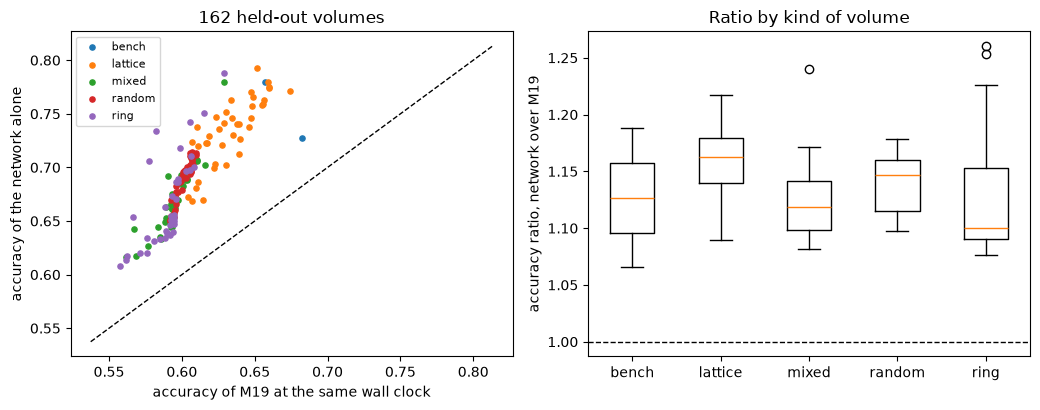

In [13]:
# left: network against M19 accuracy, one point per volume; right: the ratio by kind
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for kind in sorted(set(kinds)):
    left.scatter(m19[kinds == kind], net[kinds == kind], s=14, label=kind)
low, high = min(m19.min(), net.min()) - 0.02, max(m19.max(), net.max()) + 0.02
left.plot([low, high], [low, high], "k--", lw=1)
left.set_xlabel("accuracy of M19 at the same wall clock")
left.set_ylabel("accuracy of the network alone")
left.set_title("162 held-out volumes")
left.legend(fontsize=8)
right.boxplot([ratio[kinds == kind] for kind in sorted(set(kinds))], tick_labels=sorted(set(kinds)))
right.axhline(1.0, color="k", ls="--", lw=1)
right.set_ylabel("accuracy ratio, network over M19")
right.set_title("Ratio by kind of volume")
fig.tight_layout()
plt.show()

Every point of the left panel lies above the diagonal and the points rise together: volumes that are easier for M19 are easier for the network, which suggests that the volume carries much of the difficulty. On the right the boxes of all five groups stay above 1.0, and rings have the longest whisker, with two outliers near 1.25. The hybrid equals the network alone at every budget, so the refinement that the wall clock paid for never changed the answer in the record. The figure is the product's record and not a new measurement, and it does not say how the network behaves outside the training families, since the held-out volumes come from the same generator and the benchmark geometries; it also says nothing on the traps' own numbers, which the earlier step showed to be lower. The last cell is the one reproduction check of the notebook.

In [14]:
# the one reproduction check: the released file is the one the card and the record describe
digest = hashlib.sha256((ROOT / "models" / "cgh-net.onnx").read_bytes()).hexdigest()
print("sha256 of the file equals the card's:", digest == card["sha256"])
listed = training["heldout_sha256"] in card["held_out"]["en"]
print("held-out hash of the training record appears in the card:", listed)

sha256 of the file equals the card's: True
held-out hash of the training record appears in the card: True


## Results

**Answer:** The network learns without example holograms because its loss, one minus the accuracy of the light its own mask makes at three depths, needs only the target and the forward model: on 24 fresh volumes it scores a median loss of 0.3102 against 0.9999 for a flat phase and 0.9829 for a random phase, and around the network's phase noise of 0.2 rad raises the loss only from 0.2825 to 0.2959 on one volume and 1.6 rad takes it to 0.8978, a smooth bowl. The cost of asking only for overlap shows on the traps: the network's median efficiency is 0.388 against 0.745 for M04, and its uniformity 0.558 against 0.803, although its accuracy is higher, 0.690 against 0.606. The record of 162 held-out volumes shows the network above the volumetric GS in all of them, a median ratio of 1.1400 and a smallest of 1.0654, and a hybrid that never improves on the network alone, 0.6869 for both. The record does not show behaviour outside the training families, does not show the training itself, which was not run here, and compares the network with one baseline at one wall clock on one machine.

## Summary

A label-free loss turns the optics into the teacher: the network's own mask is propagated to three depths and compared with the target, and 512000 targets drawn from a seeded generator were enough to make the loss low and smooth around the learned phase. What the loss contains is what the network optimises, so it wins on image overlap, 1.1400 times the volumetric GS in the median on 162 held-out volumes, and loses on trap efficiency and uniformity. The next notebook runs the network against the classical volumetric loop on a case of the product and asks which of the two views a trap array should be judged by.

## References

- Eybposh, Caira, Atisa, Chakravarthula and Pégard, "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- onnxruntime 1.31.1 (MIT), https://pypi.org/pypi/onnxruntime/json and https://pypi.org/project/onnxruntime/.